In [23]:
import warnings
warnings.filterwarnings('ignore')

In [24]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from scipy import stats
import tensorflow as tf
import seaborn as sns
from pylab import rcParams
from sklearn.model_selection import train_test_split
from keras.models import Model, load_model
from keras.layers import Input, Dense
from keras.callbacks import ModelCheckpoint, TensorBoard
from keras import regularizers

%matplotlib inline

sns.set(style='whitegrid', palette='muted', font_scale=1.5)



In [ ]:
trainfile = "C:\\Users\\LOUAY\\OneDrive\\Bureau\\pwc stage 4 eme fraud\\data\\scaled_training_dataset.csv"
testfile = "C:\\Users\\LOUAY\\OneDrive\\Bureau\\pwc stage 4 eme fraud\\data\\scaled_test_dataset.csv"
train_data = pd.read_csv(trainfile)
test_data = pd.read_csv(testfile)


In [26]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Define the card information features
card_info_features = ['amt',
'amt_rolling_mean_7d',
'avg_daily_trans',
'num_trans_per_card',
'category_diversity',
'age_spend_ratio'
]

# Select only the card information features
card_info_data = train_data[card_info_features]

# Handle missing values if any
card_info_data = card_info_data.fillna(card_info_data.mean())
card_info_data_scaled = card_info_data


In [27]:
test_data_feat = test_data[card_info_features]

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pyod.models.knn import KNN
from sklearn.metrics import f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, accuracy_score
import itertools

def evaluate_knn(train_data_scaled, test_data_scaled, test_labels, contamination=0.06):
    # Initialize the KNN model
    clf = KNN(contamination=contamination, n_neighbors=5, method='largest')
    clf.fit(train_data_scaled)  # Fit on the training data

    # Get the anomaly scores for the test data
    y_scores = clf.decision_function(test_data_scaled)

    # Define the actual fraud labels for the test data
    actual_fraud = test_labels

    # Initialize variables to store the best F1 score and corresponding threshold
    best_f1 = 0
    best_threshold = 0
    best_confusion_matrix = None

    # Define a range of thresholds to evaluate
    thresholds = np.linspace(min(y_scores), max(y_scores), 100)

    # Store F1 scores and confusion matrix components for plotting
    f1_scores = []
    precision_scores = []
    recall_scores = []
    tn_values = []
    fp_values = []
    fn_values = []
    tp_values = []

    # Loop over thresholds to find the best one
    for threshold in thresholds:
        # Predict anomalies based on the current threshold
        anomalies = y_scores > threshold
        
        # Calculate the F1 score, precision, and recall
        current_f1 = f1_score(actual_fraud, anomalies)
        current_precision = precision_score(actual_fraud, anomalies)
        current_recall = recall_score(actual_fraud, anomalies)
        
        f1_scores.append(current_f1)
        precision_scores.append(current_precision)
        recall_scores.append(current_recall)
        
        # Calculate the confusion matrix
        cm = confusion_matrix(actual_fraud, anomalies)
        tn, fp, fn, tp = cm.ravel()
        tn_values.append(tn)
        fp_values.append(fp)
        fn_values.append(fn)
        tp_values.append(tp)
        
        # Check if this is the best F1 score
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold
            best_confusion_matrix = cm

    # Plot the F1 scores, precision, and recall against the thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, f1_scores, label='F1 Score', color='blue')
    plt.plot(thresholds, precision_scores, label='Precision', color='green')
    plt.plot(thresholds, recall_scores, label='Recall', color='orange')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('F1 Score, Precision, and Recall vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, tp_values, label='True Positives', color='blue')
    plt.plot(thresholds, fp_values, label='False Positives', color='orange')
    plt.plot(thresholds, fn_values, label='False Negatives', color='green')
    plt.plot(thresholds, tn_values, label='True Negatives', color='purple')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('Confusion Matrix Components vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(actual_fraud, y_scores)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

    # Print the best threshold and corresponding F1 score and confusion matrix
    print(f"Best threshold for highest F1 score: {best_threshold}")
    print(f"Highest F1 score: {best_f1}")
    print("Best Confusion Matrix at Best Threshold:")
    print(best_confusion_matrix)

    # Calculate and print additional metrics at the best threshold
    y_pred_best = y_scores > best_threshold
    accuracy = accuracy_score(actual_fraud, y_pred_best)
    precision = precision_score(actual_fraud, y_pred_best)
    recall = recall_score(actual_fraud, y_pred_best)
    f1 = f1_score(actual_fraud, y_pred_best)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")

    # Plot confusion matrix at the best threshold
    cm = confusion_matrix(actual_fraud, y_pred_best)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Non-Fraud', 'Fraud'], rotation=45)
    plt.yticks(tick_marks, ['Non-Fraud', 'Fraud'])

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()



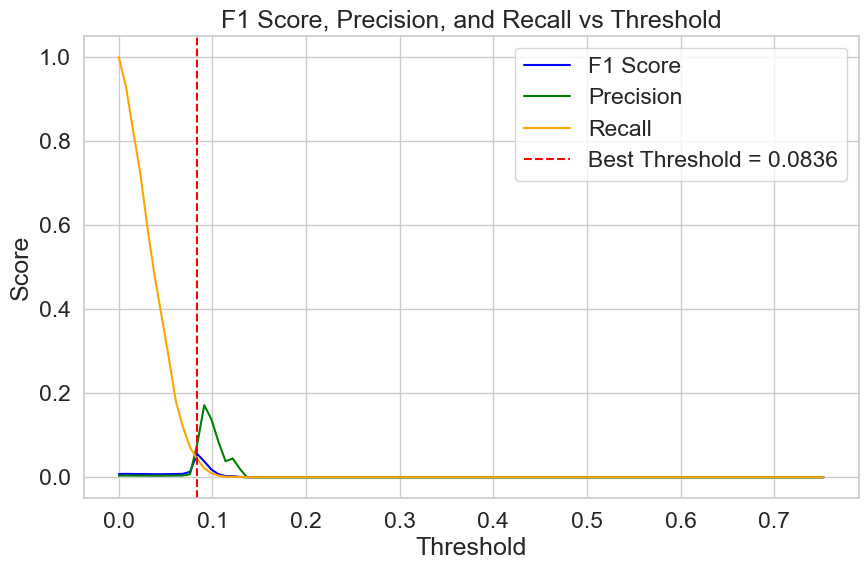

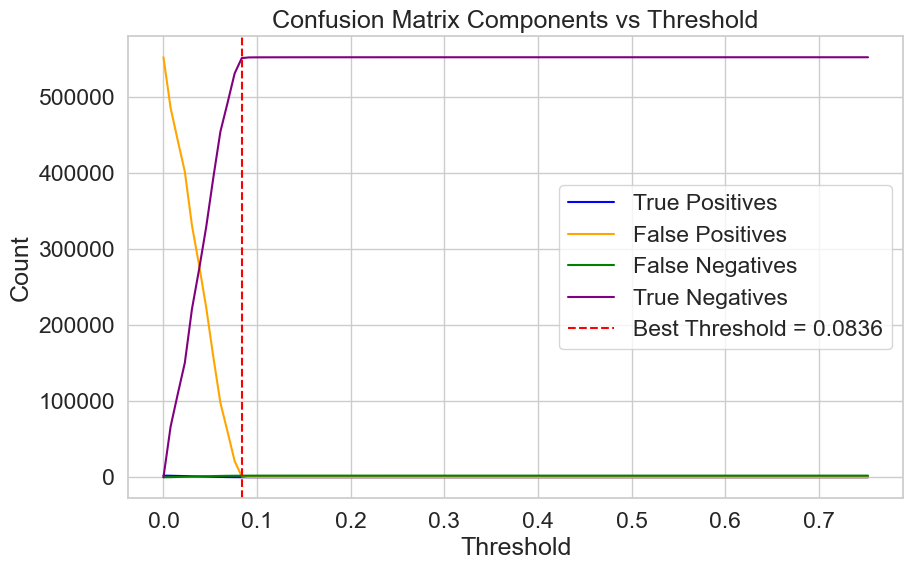

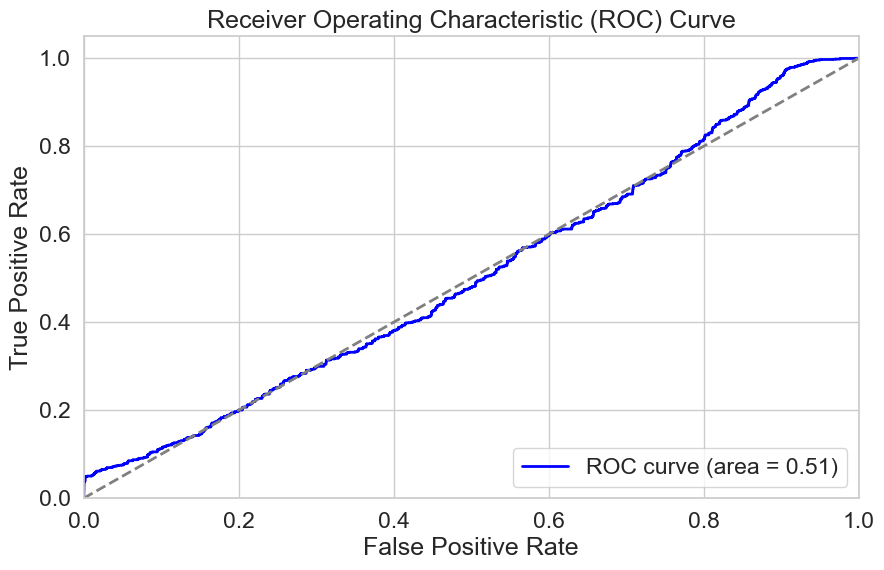

Best threshold for highest F1 score: 0.08363576509973308
Highest F1 score: 0.05560592323964944
Best Confusion Matrix at Best Threshold:
[[551578   1092]
 [  2033     92]]
Accuracy: 0.9944
Precision: 0.0777
Recall: 0.0433
F1 Score: 0.0556
AUC: 0.5057


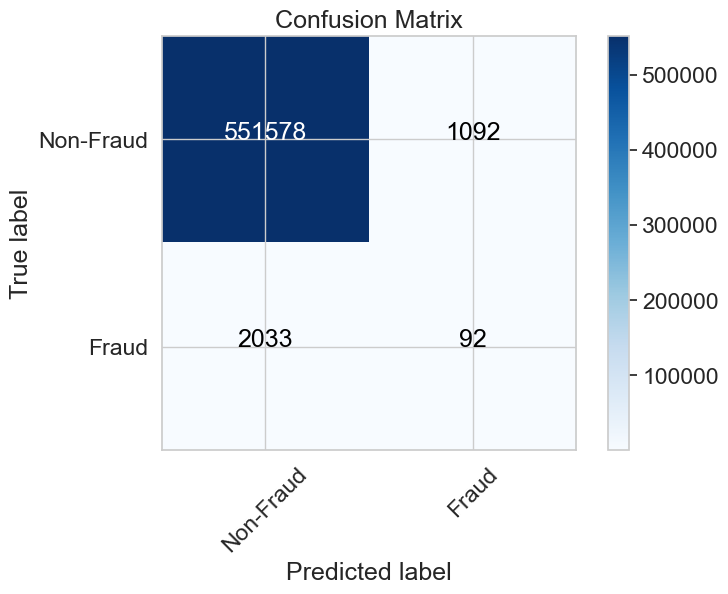

In [9]:
evaluate_knn(card_info_data_scaled, test_data_feat, test_data['is_fraud'].values)

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pyod.models.lof import LOF
from sklearn.metrics import f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, accuracy_score
import itertools

def evaluate_lof(train_data_scaled, test_data_scaled, test_labels, contamination=0.06):
    # Initialize the LOF model
    clf = LOF(contamination=contamination, n_neighbors=20, novelty=True)
    clf.fit(train_data_scaled)  # Fit on the training data

    # Get the anomaly scores for the test data
    y_scores = clf.decision_function(test_data_scaled)

    # Define the actual fraud labels for the test data
    actual_fraud = test_labels

    # Initialize variables to store the best F1 score and corresponding threshold
    best_f1 = 0
    best_threshold = 0
    best_confusion_matrix = None

    # Define a range of thresholds to evaluate
    thresholds = np.linspace(min(y_scores), max(y_scores), 100)

    # Store F1 scores and confusion matrix components for plotting
    f1_scores = []
    precision_scores = []
    recall_scores = []
    tn_values = []
    fp_values = []
    fn_values = []
    tp_values = []

    # Loop over thresholds to find the best one
    for threshold in thresholds:
        # Predict anomalies based on the current threshold
        anomalies = y_scores < threshold  # LOF scores are lower for anomalies
        
        # Calculate the F1 score, precision, and recall
        current_f1 = f1_score(actual_fraud, anomalies)
        current_precision = precision_score(actual_fraud, anomalies)
        current_recall = recall_score(actual_fraud, anomalies)
        
        f1_scores.append(current_f1)
        precision_scores.append(current_precision)
        recall_scores.append(current_recall)
        
        # Calculate the confusion matrix
        cm = confusion_matrix(actual_fraud, anomalies)
        tn, fp, fn, tp = cm.ravel()
        tn_values.append(tn)
        fp_values.append(fp)
        fn_values.append(fn)
        tp_values.append(tp)
        
        # Check if this is the best F1 score
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold
            best_confusion_matrix = cm

    # Plot the F1 scores, precision, and recall against the thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, f1_scores, label='F1 Score', color='blue')
    plt.plot(thresholds, precision_scores, label='Precision', color='green')
    plt.plot(thresholds, recall_scores, label='Recall', color='orange')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('F1 Score, Precision, and Recall vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, tp_values, label='True Positives', color='blue')
    plt.plot(thresholds, fp_values, label='False Positives', color='orange')
    plt.plot(thresholds, fn_values, label='False Negatives', color='green')
    plt.plot(thresholds, tn_values, label='True Negatives', color='purple')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('Confusion Matrix Components vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(actual_fraud, y_scores)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

    # Print the best threshold and corresponding F1 score and confusion matrix
    print(f"Best threshold for highest F1 score: {best_threshold}")
    print(f"Highest F1 score: {best_f1}")
    print("Best Confusion Matrix at Best Threshold:")
    print(best_confusion_matrix)

    # Calculate and print additional metrics at the best threshold
    y_pred_best = y_scores < best_threshold
    accuracy = accuracy_score(actual_fraud, y_pred_best)
    precision = precision_score(actual_fraud, y_pred_best)
    recall = recall_score(actual_fraud, y_pred_best)
    f1 = f1_score(actual_fraud, y_pred_best)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")

    # Plot confusion matrix at the best threshold
    cm = confusion_matrix(actual_fraud, y_pred_best)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Non-Fraud', 'Fraud'], rotation=45)
    plt.yticks(tick_marks, ['Non-Fraud', 'Fraud'])

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()



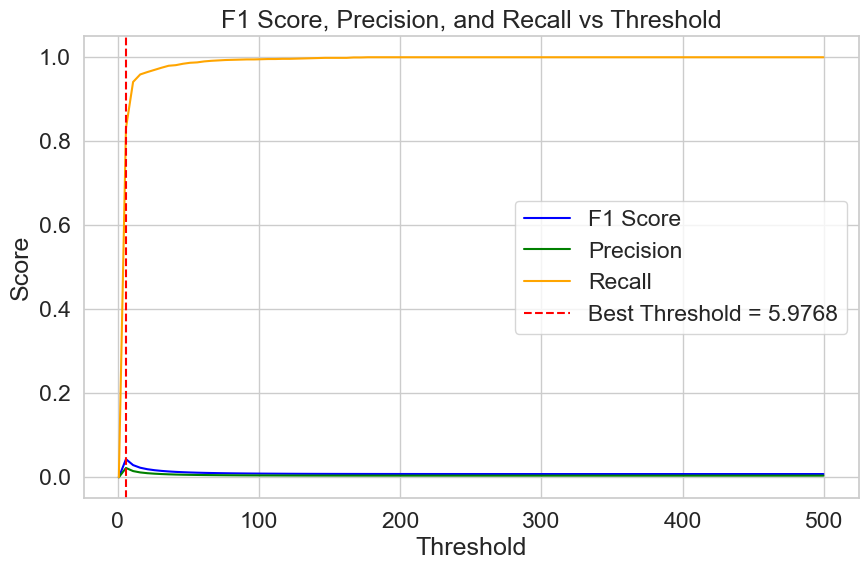

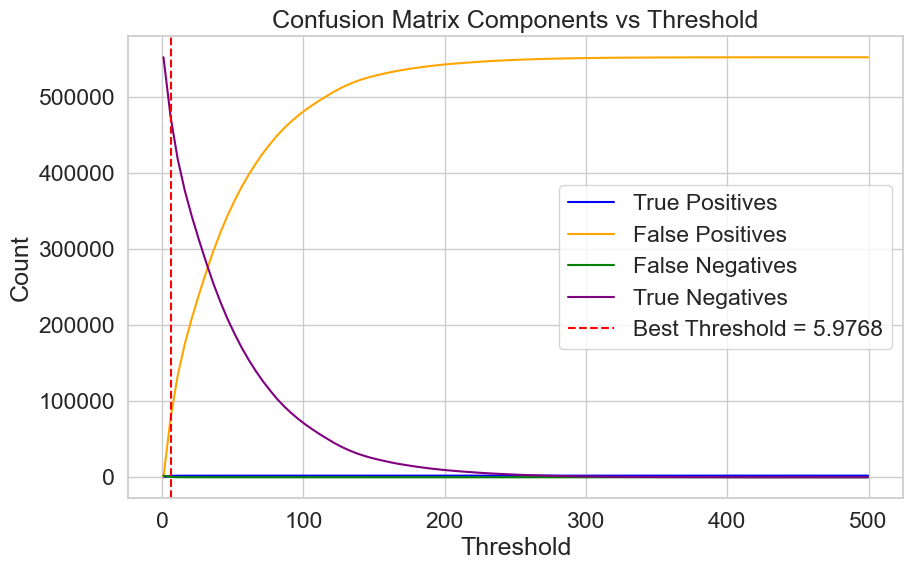

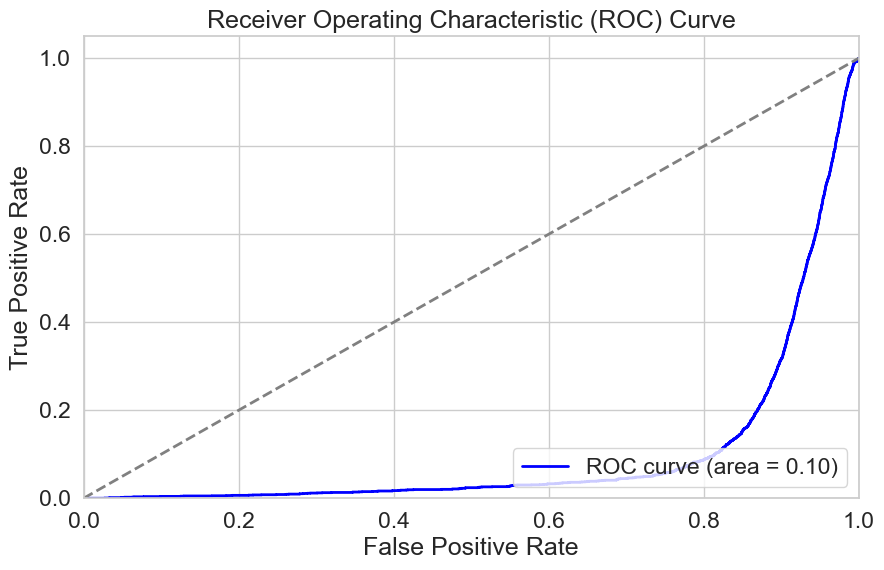

Best threshold for highest F1 score: 5.976828923812326
Highest F1 score: 0.04300394486923489
Best Confusion Matrix at Best Threshold:
[[474429  78241]
 [   359   1766]]
Accuracy: 0.8583
Precision: 0.0221
Recall: 0.8311
F1 Score: 0.0430
AUC: 0.1004


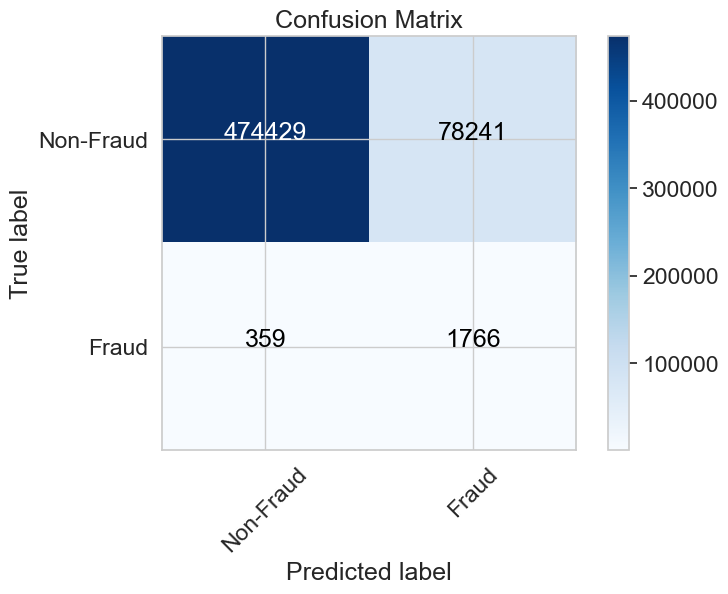

In [13]:
evaluate_lof(card_info_data_scaled, test_data_feat, test_data['is_fraud'].values)

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyod.models.iforest import IForest
from pyod.models.gmm import GMM
from sklearn.metrics import f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, accuracy_score
import itertools

def evaluate_combined_models(train_data_scaled, test_data_scaled, test_labels, contamination=0.06):
    # Initialize models
    models = {
        'IForest': IForest(contamination=contamination, random_state=42),
        'GMM': GMM(contamination=contamination, random_state=42)
    }

    # Fit models
    for name, model in models.items():
        model.fit(train_data_scaled)

    # Get anomaly scores for the test data
    y_scores = {name: model.decision_function(test_data_scaled) for name, model in models.items()}

    # Initialize variables to store the best F1 score and corresponding threshold
    best_f1 = 0
    best_threshold = 0
    best_confusion_matrix = None

    # Define a range of thresholds to evaluate
    thresholds = np.linspace(min(min(scores) for scores in y_scores.values()), 
                             max(max(scores) for scores in y_scores.values()), 
                             100)

    # Store metrics for plotting
    f1_scores = []
    precision_scores = []
    recall_scores = []
    tn_values = []
    fp_values = []
    fn_values = []
    tp_values = []

    # Loop over thresholds to find the best one
    for threshold in thresholds:
        # Combine predictions from all models using average scoring
        combined_scores = np.mean([scores for scores in y_scores.values()], axis=0)
        combined_predictions = combined_scores > threshold
        
        # Calculate metrics
        current_f1 = f1_score(test_labels, combined_predictions)
        current_precision = precision_score(test_labels, combined_predictions)
        current_recall = recall_score(test_labels, combined_predictions)
        
        f1_scores.append(current_f1)
        precision_scores.append(current_precision)
        recall_scores.append(current_recall)
        
        # Calculate confusion matrix
        cm = confusion_matrix(test_labels, combined_predictions)
        if cm.size == 4:  # Ensure correct size
            tn, fp, fn, tp = cm.ravel()
            tn_values.append(tn)
            fp_values.append(fp)
            fn_values.append(fn)
            tp_values.append(tp)
        else:
            tn_values.append(0)
            fp_values.append(0)
            fn_values.append(0)
            tp_values.append(0)
        
        # Check if this is the best F1 score
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold
            best_confusion_matrix = cm

    # Plot metrics vs thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, f1_scores, label='F1 Score', color='blue')
    plt.plot(thresholds, precision_scores, label='Precision', color='green')
    plt.plot(thresholds, recall_scores, label='Recall', color='orange')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('F1 Score, Precision, and Recall vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, tp_values, label='True Positives', color='blue')
    plt.plot(thresholds, fp_values, label='False Positives', color='orange')
    plt.plot(thresholds, fn_values, label='False Negatives', color='green')
    plt.plot(thresholds, tn_values, label='True Negatives', color='purple')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('Confusion Matrix Components vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Calculate ROC curve and AUC
    combined_scores = np.mean([scores for scores in y_scores.values()], axis=0)
    fpr, tpr, _ = roc_curve(test_labels, combined_scores)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

    # Print results
    print(f"Best threshold for highest F1 score: {best_threshold}")
    print(f"Highest F1 score: {best_f1}")
    print("Best Confusion Matrix at Best Threshold:")
    print(best_confusion_matrix)

    # Calculate and print additional metrics at the best threshold
    y_pred_best = combined_scores > best_threshold
    accuracy = accuracy_score(test_labels, y_pred_best)
    precision = precision_score(test_labels, y_pred_best)
    recall = recall_score(test_labels, y_pred_best)
    f1 = f1_score(test_labels, y_pred_best)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")

    # Plot confusion matrix at the best threshold
    cm = confusion_matrix(test_labels, y_pred_best)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Non-Fraud', 'Fraud'], rotation=45)
    plt.yticks(tick_marks, ['Non-Fraud', 'Fraud'])

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()




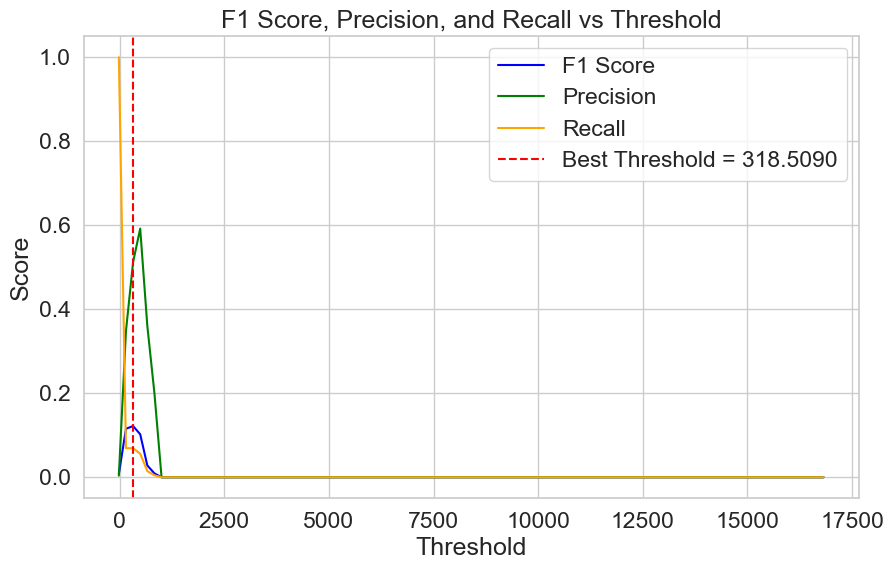

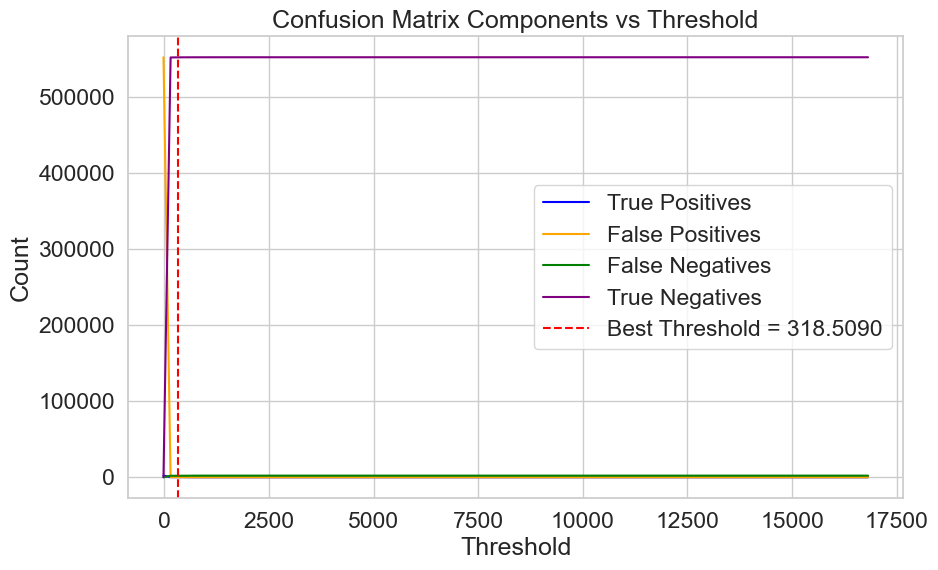

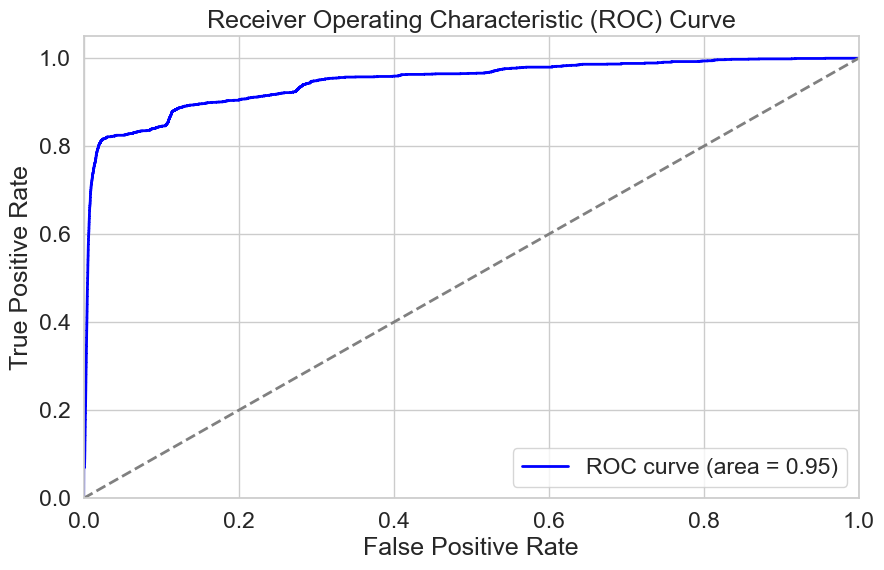

Best threshold for highest F1 score: 318.5090350555915
Highest F1 score: 0.12189054726368159
Best Confusion Matrix at Best Threshold:
[[552530    140]
 [  1978    147]]
Accuracy: 0.9962
Precision: 0.5122
Recall: 0.0692
F1 Score: 0.1219
AUC: 0.9462


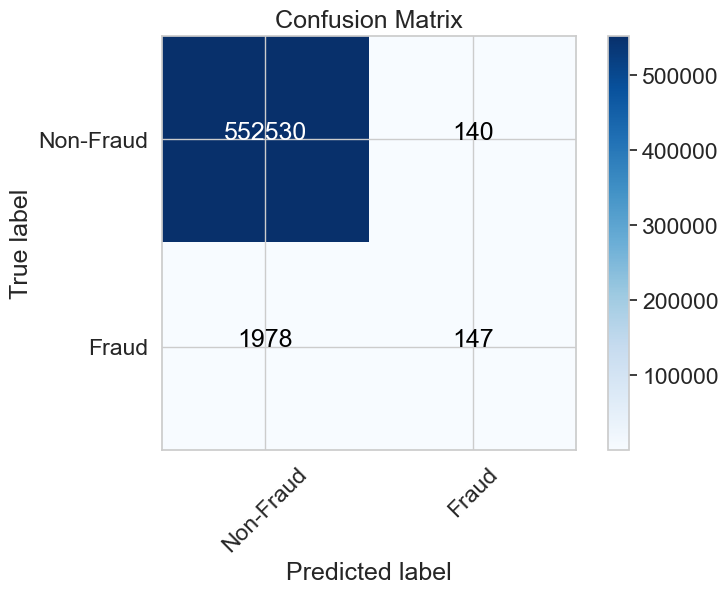

In [11]:
evaluate_combined_models(card_info_data_scaled, test_data_feat, test_data['is_fraud'].values)

In [15]:
pip install combo

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for combo: filename=combo-0.1.3-py3-none-any.whl size=42914 sha256=ac13edc17275b9c007cc7b1b18d1edc77eddf9e60f3f8dd32595ef2b80ad9606
  Stored in directory: c:\users\rassa\appdata\local\pip\cache\wheels\b7\4b\9a\b3fc6e167972ed8eec21e6e9e476457a8b05d8918dc80b649a
Successfully built combo
Note: you may need to restart the kernel to use updated packages.


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from pyod.models.feature_bagging import FeatureBagging
from pyod.models.hbos import HBOS
from sklearn.metrics import f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, accuracy_score
import itertools

def evaluate_model(model, train_data_scaled, test_data, test_labels):
    """
    Evaluate the given anomaly detection model using F1 score, precision, recall, ROC curve, and confusion matrix.
    
    Parameters:
    - model: PyOD model instance
    - train_data_scaled: Scaled training data
    - test_data: Test data
    - test_labels: True labels for the test data

    Returns:
    - None
    """
    # Fit the model
    model.fit(train_data_scaled)
    
    # Get anomaly scores for the test data
    y_scores = model.decision_function(test_data)
    
    # Define the actual fraud labels for the test data
    actual_fraud = test_labels

    # Initialize variables to store the best F1 score and corresponding threshold
    best_f1 = 0
    best_threshold = 0
    best_confusion_matrix = None

    # Define a range of thresholds to evaluate
    thresholds = np.linspace(min(y_scores), max(y_scores), 100)

    # Store metrics for plotting
    f1_scores = []
    precision_scores = []
    recall_scores = []
    tn_values = []
    fp_values = []
    fn_values = []
    tp_values = []

    # Loop over thresholds to find the best one
    for threshold in thresholds:
        # Predict anomalies based on the current threshold
        anomalies = y_scores < threshold
        
        # Calculate metrics
        current_f1 = f1_score(actual_fraud, anomalies)
        current_precision = precision_score(actual_fraud, anomalies)
        current_recall = recall_score(actual_fraud, anomalies)
        
        f1_scores.append(current_f1)
        precision_scores.append(current_precision)
        recall_scores.append(current_recall)
        
        # Calculate the confusion matrix
        cm = confusion_matrix(actual_fraud, anomalies)
        if cm.size == 4:  # Ensure correct size
            tn, fp, fn, tp = cm.ravel()
            tn_values.append(tn)
            fp_values.append(fp)
            fn_values.append(fn)
            tp_values.append(tp)
        else:
            tn_values.append(0)
            fp_values.append(0)
            fn_values.append(0)
            tp_values.append(0)
        
        # Check if this is the best F1 score
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold
            best_confusion_matrix = cm

    # Plot metrics vs thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, f1_scores, label='F1 Score', color='blue')
    plt.plot(thresholds, precision_scores, label='Precision', color='green')
    plt.plot(thresholds, recall_scores, label='Recall', color='orange')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('F1 Score, Precision, and Recall vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, tp_values, label='True Positives', color='blue')
    plt.plot(thresholds, fp_values, label='False Positives', color='orange')
    plt.plot(thresholds, fn_values, label='False Negatives', color='green')
    plt.plot(thresholds, tn_values, label='True Negatives', color='purple')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('Confusion Matrix Components vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(actual_fraud, y_scores)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

    # Print results
    print(f"Best threshold for highest F1 score: {best_threshold}")
    print(f"Highest F1 score: {best_f1}")
    print("Best Confusion Matrix at Best Threshold:")
    print(best_confusion_matrix)

    # Calculate and print additional metrics at the best threshold
    y_pred_best = y_scores < best_threshold
    accuracy = accuracy_score(actual_fraud, y_pred_best)
    precision = precision_score(actual_fraud, y_pred_best)
    recall = recall_score(actual_fraud, y_pred_best)
    f1 = f1_score(actual_fraud, y_pred_best)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")

    # Plot confusion matrix at the best threshold
    cm = confusion_matrix(actual_fraud, y_pred_best)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Non-Fraud', 'Fraud'], rotation=45)
    plt.yticks(tick_marks, ['Non-Fraud', 'Fraud'])

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()


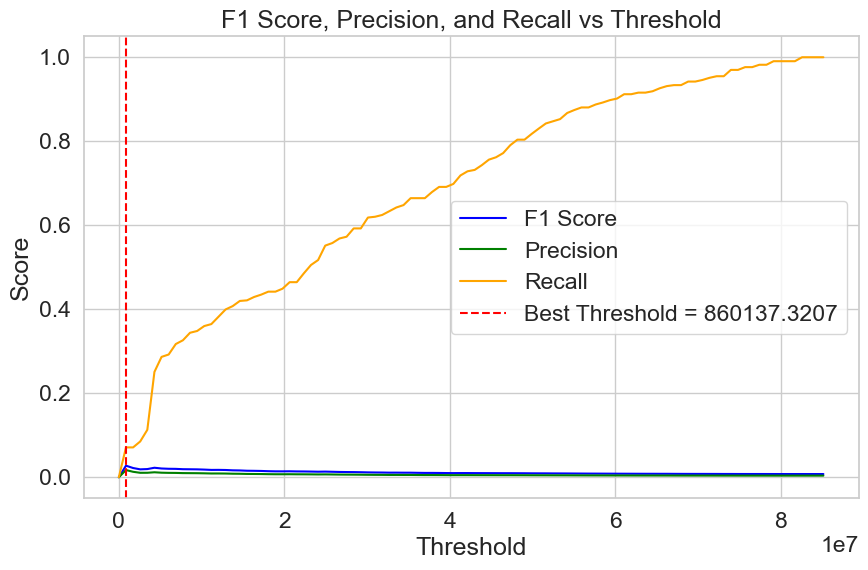

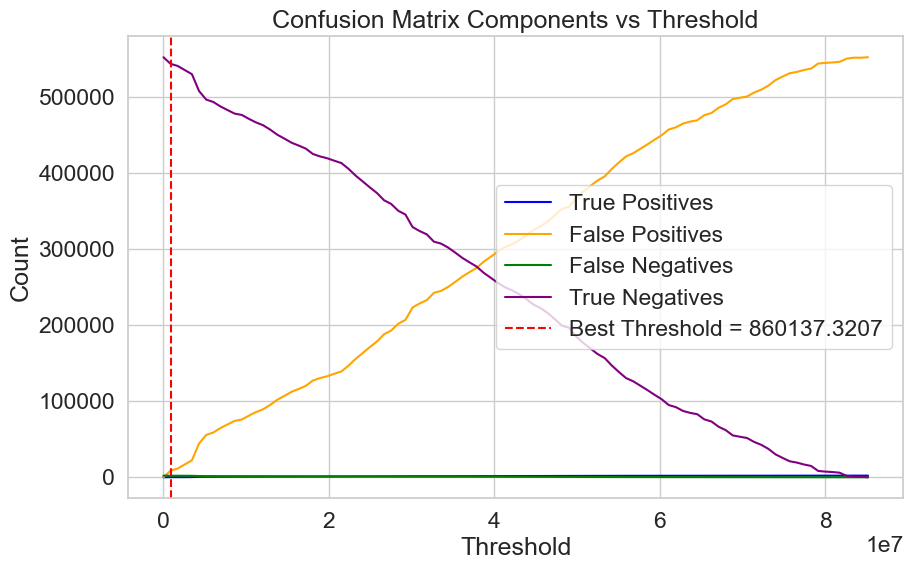

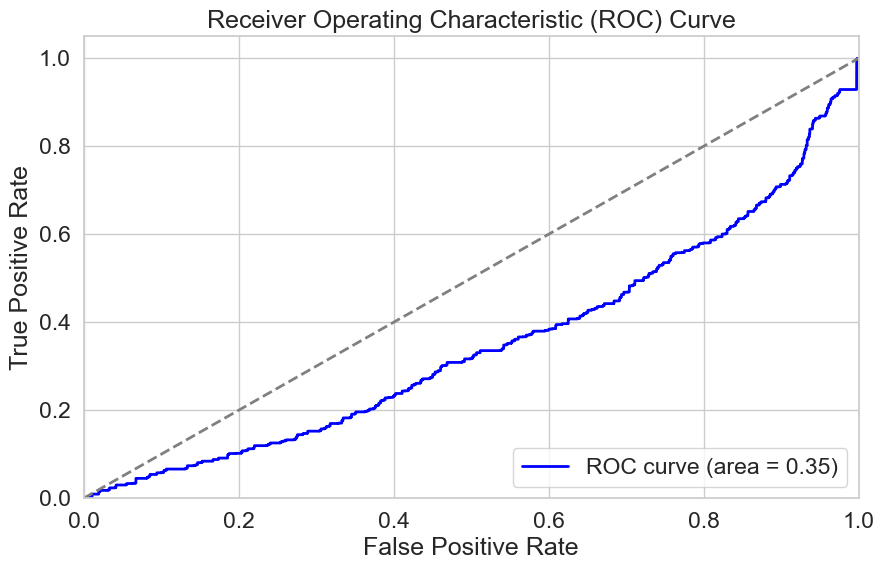

Best threshold for highest F1 score: 860137.3207215641
Highest F1 score: 0.027597550945810106
Best Confusion Matrix at Best Threshold:
[[544003   8667]
 [  1974    151]]
Accuracy: 0.9808
Precision: 0.0171
Recall: 0.0711
F1 Score: 0.0276
AUC: 0.3499


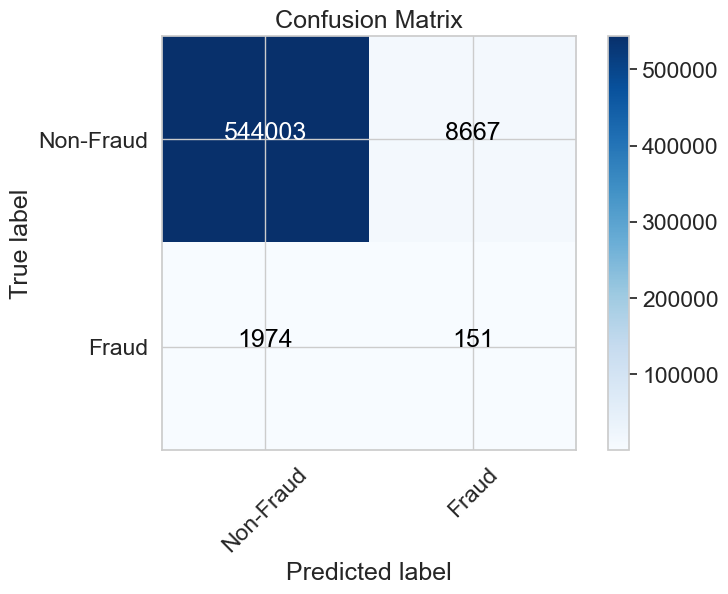

In [17]:
# Example usage with Feature Bagging
from pyod.models.feature_bagging import FeatureBagging

feature_bagging_model = FeatureBagging()
evaluate_model(feature_bagging_model, card_info_data_scaled, test_data_feat, test_data['is_fraud'].values)

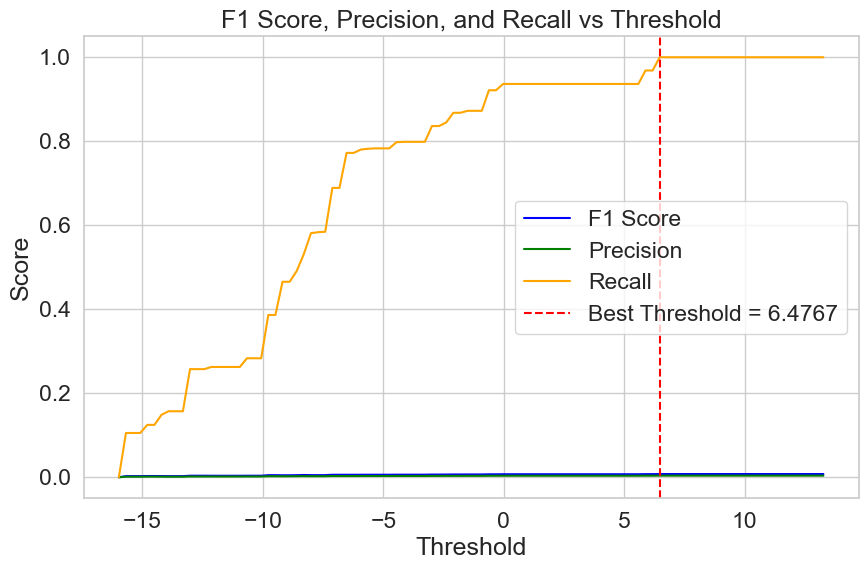

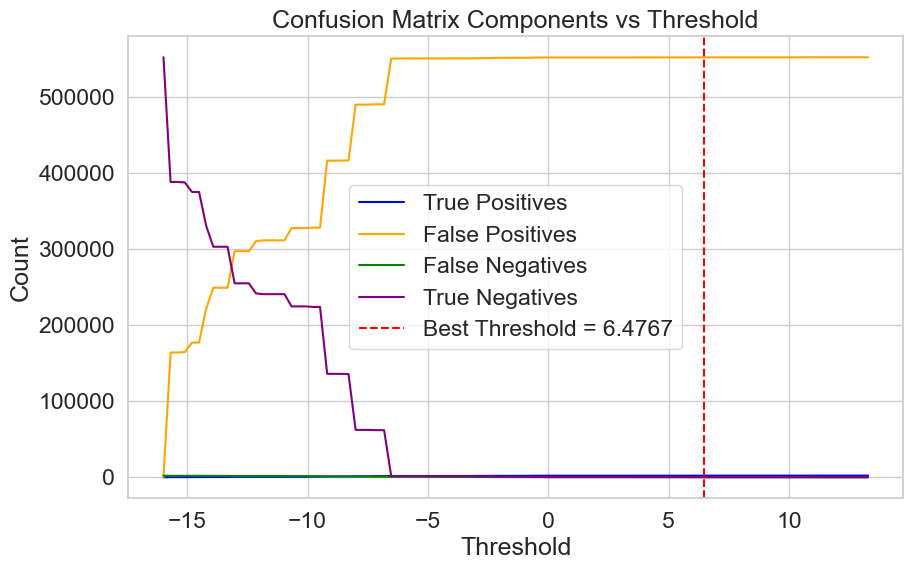

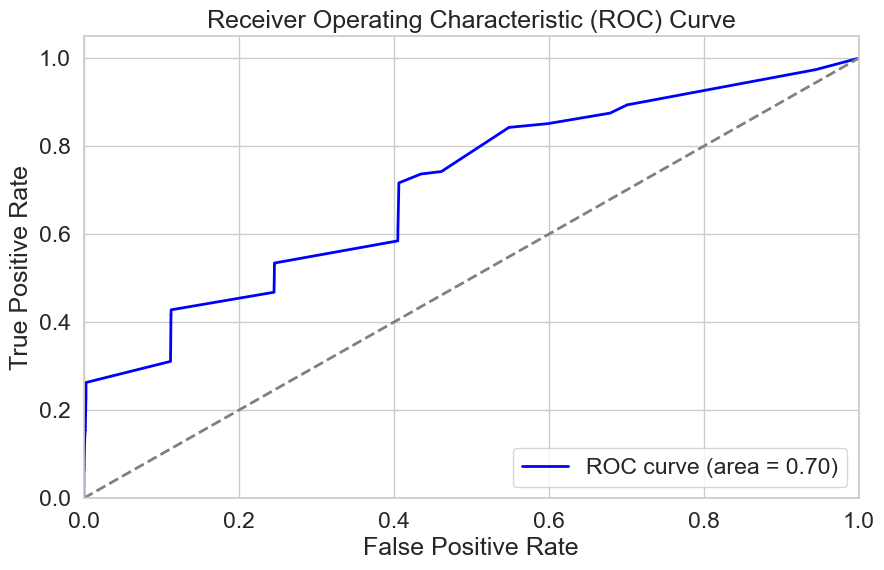

Best threshold for highest F1 score: 6.476710199935027
Highest F1 score: 0.007633340996609001
Best Confusion Matrix at Best Threshold:
[[   152 552518]
 [     0   2125]]
Accuracy: 0.0041
Precision: 0.0038
Recall: 1.0000
F1 Score: 0.0076
AUC: 0.7043


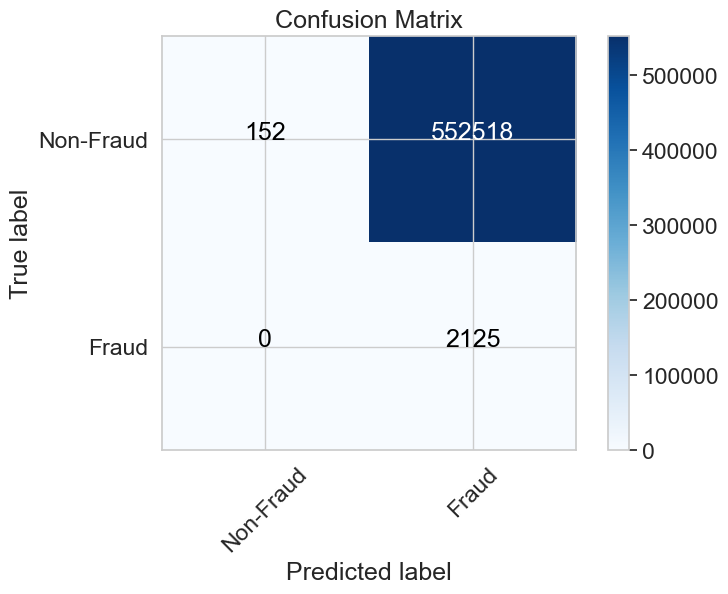

In [18]:
# Example usage with HBOS
from pyod.models.hbos import HBOS

hbos_model = HBOS()
evaluate_model(hbos_model, card_info_data_scaled, test_data_feat, test_data['is_fraud'].values)

Best threshold for highest F1 score: 0.8455031589366261
Highest F1 score: 0.3370886013676391
Accuracy: 0.9858
Precision: 0.1492
Recall: 0.5732
F1 Score: 0.2367
AUC: 0.9491


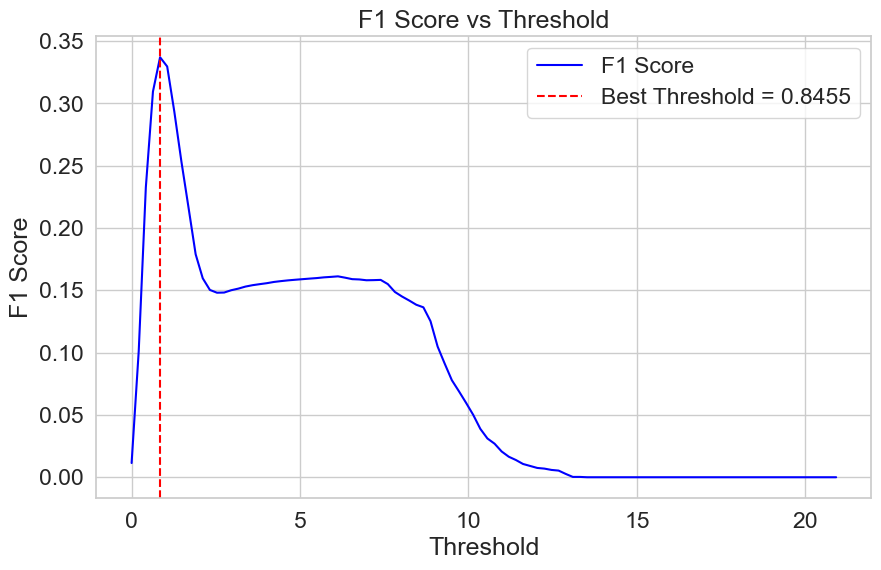

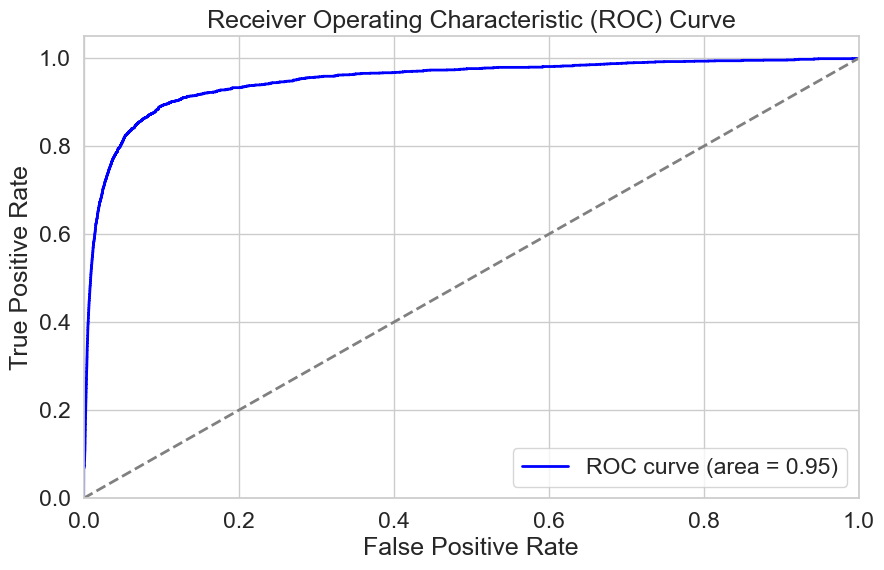

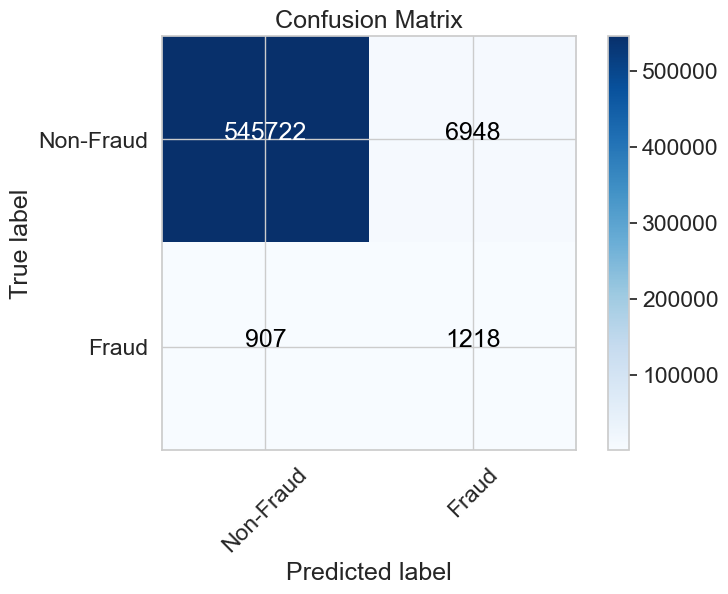

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix, accuracy_score
import itertools

def pca_anomaly_detection(train_data, test_data, n_components=2):
    # Define the features to use
    card_info_features = ['amt', 'amt_rolling_mean_7d', 'avg_daily_trans', 'num_trans_per_card', 
                          'category_diversity', 'age_spend_ratio']
    
    # Prepare data
    train_data_feat = train_data[card_info_features]
    test_data_feat = test_data[card_info_features]
    
    # Standardize the data
    scaler = StandardScaler()
    train_data_scaled = scaler.fit_transform(train_data_feat)
    test_data_scaled = scaler.transform(test_data_feat)
    
    # Apply PCA
    pca = PCA(n_components=n_components)
    pca.fit(train_data_scaled)
    
    # Reconstruct the data
    train_reconstructed = pca.inverse_transform(pca.transform(train_data_scaled))
    test_reconstructed = pca.inverse_transform(pca.transform(test_data_scaled))
    
    # Calculate reconstruction error
    train_reconstruction_error = np.mean(np.abs(train_data_scaled - train_reconstructed), axis=1)
    test_reconstruction_error = np.mean(np.abs(test_data_scaled - test_reconstructed), axis=1)
    
    # Initialize variables to find the best threshold based on F1 score
    best_f1 = 0
    best_threshold = 0
    
    # Define a range of thresholds to evaluate
    thresholds = np.linspace(min(train_reconstruction_error), max(train_reconstruction_error), 100)
    
    # Store F1 scores for plotting
    f1_scores = []
    
    # Define the actual fraud labels for the training data
    actual_fraud_train = train_data['is_fraud'].values
    
    # Loop over thresholds to find the best one
    for threshold in thresholds:
        # Predict anomalies based on the current threshold
        train_anomalies = train_reconstruction_error > threshold
        
        # Calculate the F1 score
        current_f1 = f1_score(actual_fraud_train, train_anomalies)
        f1_scores.append(current_f1)
        
        # Check if this is the best F1 score
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold
    
    # Apply the best threshold to the test data
    test_anomalies = test_reconstruction_error > best_threshold
    
    # Define the actual fraud labels for the test data
    actual_fraud_test = test_data['is_fraud'].values
    
    # Calculate performance metrics
    accuracy = accuracy_score(actual_fraud_test, test_anomalies)
    precision = precision_score(actual_fraud_test, test_anomalies)
    recall = recall_score(actual_fraud_test, test_anomalies)
    f1 = f1_score(actual_fraud_test, test_anomalies)
    
    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(actual_fraud_test, test_reconstruction_error)
    roc_auc = auc(fpr, tpr)
    
    # Print results
    print(f"Best threshold for highest F1 score: {best_threshold}")
    print(f"Highest F1 score: {best_f1}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")
    
    # Plot F1 scores vs Thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, f1_scores, label='F1 Score', color='blue')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('F1 Score vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # Plot ROC curve
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
    
    # Plot confusion matrix at the best threshold
    cm = confusion_matrix(actual_fraud_test, test_anomalies)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Non-Fraud', 'Fraud'], rotation=45)
    plt.yticks(tick_marks, ['Non-Fraud', 'Fraud'])
    
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

# Example usage
pca_anomaly_detection(train_data, test_data)


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from pyod.models.iforest import IForest
from sklearn.metrics import (f1_score, precision_score, recall_score, 
                             roc_curve, auc, confusion_matrix, accuracy_score)
import itertools

def evaluate_iforest_model(train_data, test_data, features, target_column, contamination=0.06):
    """
    Evaluate the Isolation Forest model on the test data and plot various performance metrics.
    
    Parameters:
    - train_data: DataFrame containing the training data.
    - test_data: DataFrame containing the test data.
    - features: List of feature names to use for the model.
    - target_column: Name of the column in test_data indicating the true labels.
    - contamination: Contamination parameter for the Isolation Forest model.
    
    Returns:
    - None
    """
    # Prepare training and test data
    card_info_data_scaled = train_data[features].fillna(train_data[features].mean())
    test_data_feat = test_data[features].fillna(test_data[features].mean())
    actual_fraud = test_data[target_column].values  # True labels from test data
    
    # Initialize and fit the Isolation Forest model
    clf = IForest(contamination=contamination, random_state=42)
    clf.fit(card_info_data_scaled)
    
    # Get the anomaly scores for the test data
    y_scores = clf.decision_function(test_data_feat)
    
    # Initialize variables to store the best F1 score and corresponding threshold
    best_f1 = 0
    best_threshold = 0
    best_confusion_matrix = None
    
    # Define a range of thresholds to evaluate
    thresholds = np.linspace(min(y_scores), max(y_scores), 100)
    
    # Store F1 scores and confusion matrix components for plotting
    f1_scores = []
    precision_scores = []
    recall_scores = []
    tn_values = []
    fp_values = []
    fn_values = []
    tp_values = []
    
    # Loop over thresholds to find the best one
    for threshold in thresholds:
        # Predict anomalies based on the current threshold
        anomalies = y_scores > threshold
        
        # Calculate the F1 score, precision, and recall
        current_f1 = f1_score(actual_fraud, anomalies)
        current_precision = precision_score(actual_fraud, anomalies)
        current_recall = recall_score(actual_fraud, anomalies)
        
        f1_scores.append(current_f1)
        precision_scores.append(current_precision)
        recall_scores.append(current_recall)
        
        # Calculate the confusion matrix
        cm = confusion_matrix(actual_fraud, anomalies)
        tn, fp, fn, tp = cm.ravel()
        tn_values.append(tn)
        fp_values.append(fp)
        fn_values.append(fn)
        tp_values.append(tp)
        
        # Check if this is the best F1 score
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = threshold
            best_confusion_matrix = cm
    
    # Plot the F1 scores, precision, and recall against the thresholds
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, f1_scores, label='F1 Score', color='blue')
    plt.plot(thresholds, precision_scores, label='Precision', color='green')
    plt.plot(thresholds, recall_scores, label='Recall', color='orange')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('F1 Score, Precision, and Recall vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, tp_values, label='True Positives', color='blue')
    plt.plot(thresholds, fp_values, label='False Positives', color='orange')
    plt.plot(thresholds, fn_values, label='False Negatives', color='green')
    plt.plot(thresholds, tn_values, label='True Negatives', color='purple')
    plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.4f}')
    plt.title('Confusion Matrix Components vs Threshold')
    plt.xlabel('Threshold')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(actual_fraud, y_scores)
    roc_auc = auc(fpr, tpr)
    
    # Plot the ROC curve
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
    
    # Print the best threshold and corresponding F1 score and confusion matrix
    print(f"Best threshold for highest F1 score: {best_threshold}")
    print(f"Highest F1 score: {best_f1}")
    print("Best Confusion Matrix at Best Threshold:")
    print(best_confusion_matrix)
    
    # Calculate and print additional metrics at the best threshold
    y_pred_best = y_scores > best_threshold
    accuracy = accuracy_score(actual_fraud, y_pred_best)
    precision = precision_score(actual_fraud, y_pred_best)
    recall = recall_score(actual_fraud, y_pred_best)
    f1 = f1_score(actual_fraud, y_pred_best)
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")
    
    # Plot confusion matrix at the best threshold
    cm = confusion_matrix(actual_fraud, y_pred_best)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['Non-Fraud', 'Fraud'], rotation=45)
    plt.yticks(tick_marks, ['Non-Fraud', 'Fraud'])
    
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()


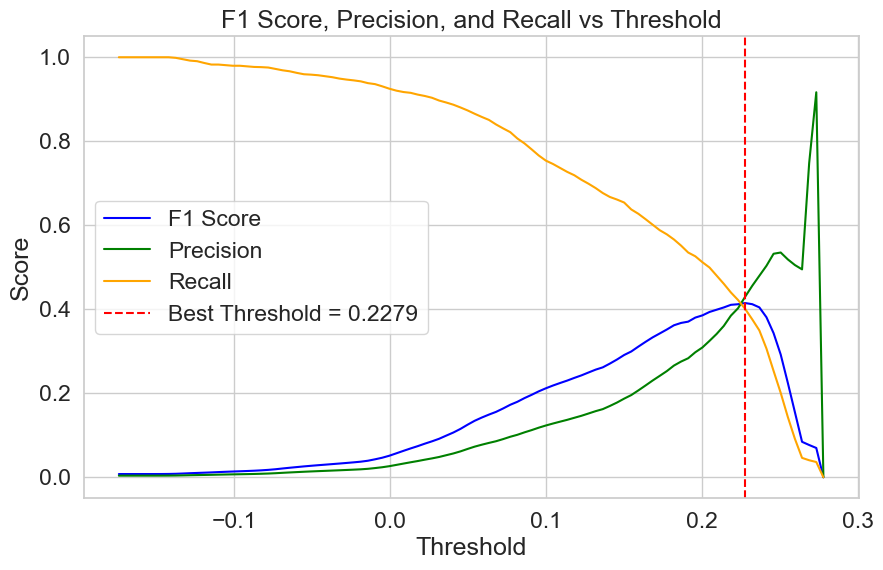

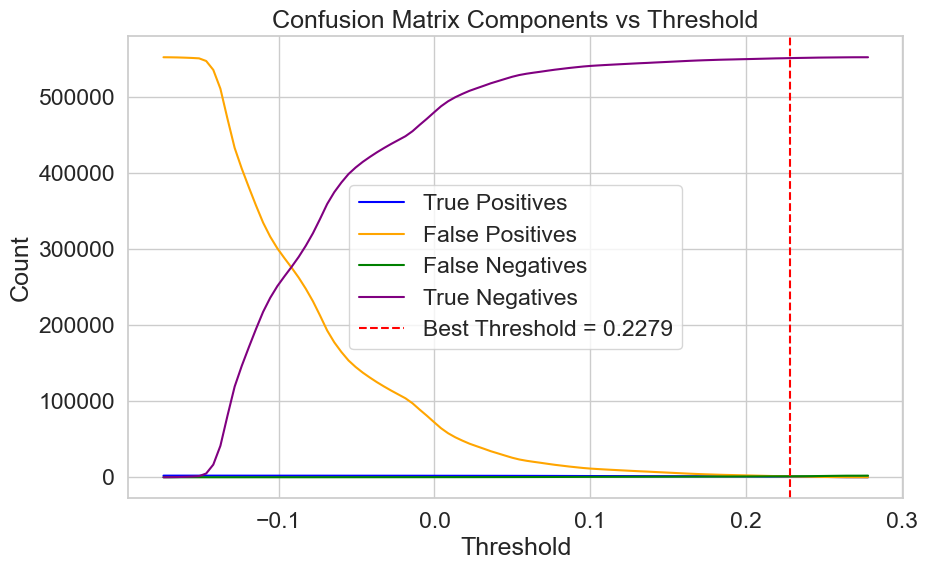

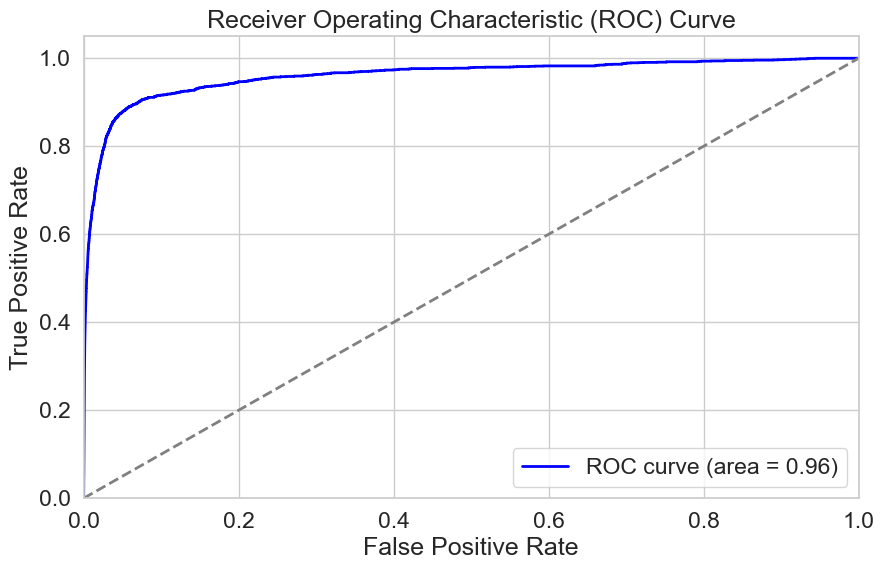

Best threshold for highest F1 score: 0.2278909954209647
Highest F1 score: 0.4148003894839338
Best Confusion Matrix at Best Threshold:
[[551539   1131]
 [  1273    852]]
Accuracy: 0.9957
Precision: 0.4297
Recall: 0.4009
F1 Score: 0.4148
AUC: 0.9601


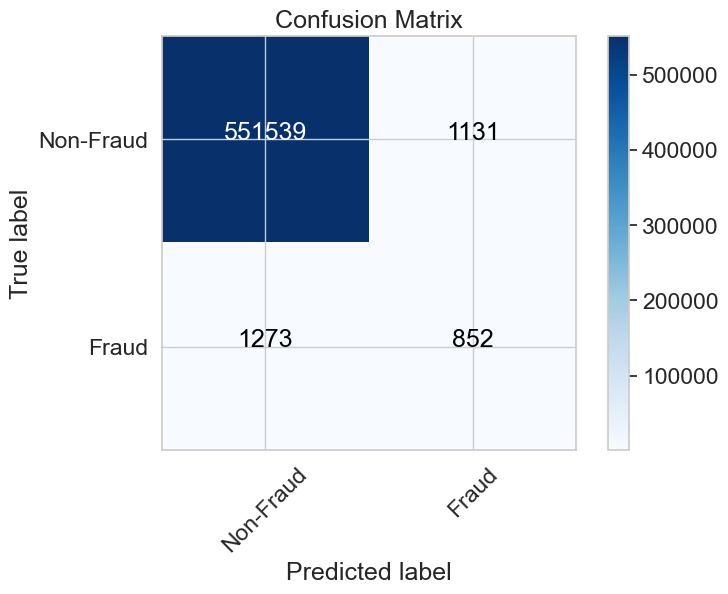

In [29]:
evaluate_iforest_model(train_data, test_data, card_info_features, target_column='is_fraud', contamination=0.06)
